## SPARCS Hospital Inpatient Discharges (2024)

Dataset: https://health.data.ny.gov/d/sf4k-39ay

API documentation: https://dev.socrata.com/foundry/health.data.ny.gov/sf4k-39ay

### Notebook map and dataframe names

Goal: predict the length of stay of a patient once admitted, from the initial diagnosis.

Exploration cells only look at the data and never modify a frame. Each frame below is built from the previous one, so every decision can be traced.

- `df_raw`: the data exactly as downloaded. Never modified.
- `df_eda`: `df_raw` plus the numeric target `los`. All rows, all columns.
- `df_nonredacted`: `df_eda` without the redacted facility records.
- `df_main`: `df_nonredacted` without newborn admissions (the cohort in scope).
- `df_newborn`: the newborn admissions, set aside.
- `df_clean`: `df_main` after dropping columns and labelling missing values. The frame used from here on.

Sections
1. Setup and load
2. First look
3. Target variable
4. Column decisions (constant, leakage, redundant pairs)
5. Row decision: redacted facility records
6. Facility and geography hierarchy
7. Feature reviews: zip code, payment typology, type of admission
8. Birth weight and the newborn cohort
9. Gender, race and ethnicity
10. Still to review
11. Build `df_clean`
12. Decision log

## 1. Setup and load

### Imports

In [ ]:
import os
import requests
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pathlib import Path

# pip install scipy

### Point to the API endpoint

The dataset page ID `sf4k-39ay` maps to a Socrata (SODA) API endpoint. Requesting `.json` from it returns records as a list of dictionaries, which pandas can turn into a DataFrame directly.

**App token (optional):** if `APP_TOKEN` is set in the `.env` file, it is sent with every request as the `X-App-Token` header, which avoids throttling. If it is empty or missing, the requests are sent without it and still work.

In [2]:
BASE_URL = "https://health.data.ny.gov/resource/sf4k-39ay.json"

load_dotenv()  # reads APP_TOKEN from the .env file at the repo root if it's set.

app_token = os.environ.get("APP_TOKEN")
HEADERS = {"X-App-Token": app_token} if app_token else {}

### Fetch Raw Data

- With over 2 million rows, we request `PAGE_SIZE` rows at a time, moving the `$offset` forward each time. We order by `:id` (a built-in unique row id) so the pages are stable and don't overlap or skip rows.
- Downloading 2.1 million rows takes a while, so we save the result to a parquet file format (`data/raw/sparcs_2024_raw.parquet`) the first time. On every later run, the notebook reads that file from disk instead of calling the API.

To force a fresh download, delete the parquet file saved locally.

In [3]:
PAGE_SIZE = 50000

In [4]:
def fetch_page(offset):
    payload = {"$limit": PAGE_SIZE, "$offset": offset, "$order": ":id"}
    resp = requests.get(BASE_URL, params=payload, timeout=120, headers=HEADERS)
    resp.raise_for_status()
    return resp.json()

In [5]:
CACHE_PATH = Path("../data/raw/sparcs_2024_raw.parquet")
CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)

In [6]:
if CACHE_PATH.exists():
    df_raw = pd.read_parquet(CACHE_PATH)
    print("loaded from cache")
else:
    pages = []
    offset = 0
    while True:
        page = fetch_page(offset)
        if not page:  # an empty page means we have gone past the last row
            break
        pages.append(page)
        print(f"fetched rows {offset:,} to {offset + len(page):,}")
        offset += PAGE_SIZE
    df_raw = pd.DataFrame([row for page in pages for row in page])
    df_raw.to_parquet(CACHE_PATH)
    print("downloaded and saved to cache.")

loaded from cache


### Sanity Check

In [7]:
try:
    count_resp = requests.get(BASE_URL,
                              params={"$select": "count(*)"},
                              headers=HEADERS, timeout=30)
    count_resp.raise_for_status()
    total_rows = int(count_resp.json()[0]["count"])

    if len(df_raw) == total_rows:
        print(f"Row count matches the API: {len(df_raw):,} rows")
    else:
        print(f"WARNING: row count mismatch. API has {total_rows:,} rows, DataFrame has {len(df_raw):,}")
except requests.RequestException as err:
    print("API not reachable, skipping the row count check:", type(err).__name__)

Row count matches the API: 2,196,737 rows


In [8]:
print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")

Rows: 2,196,737
Columns: 33


## 2. First look at the data

In [9]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.float_format", "{:,.2f}".format)

In [10]:
print(df_raw.columns)

Index(['health_service_area', 'hospital_county',
       'operating_certificate_number', 'permanent_facility_id',
       'facility_name', 'age_group', 'zip_code', 'gender', 'race', 'ethnicity',
       'length_of_stay', 'type_of_admission', 'patient_disposition',
       'discharge_year', 'ccsr_diagnosis_code', 'ccsr_diagnosis_description',
       'apr_drg_code', 'apr_drg_description', 'apr_mdc_code',
       'apr_mdc_description', 'apr_severity_of_illness_code',
       'apr_severity_of_illness', 'apr_risk_of_mortality',
       'apr_medical_surgical', 'payment_typology_1',
       'emergency_department_indicator', 'total_charges', 'total_costs',
       'ccsr_procedure_code', 'ccsr_procedure_description',
       'payment_typology_2', 'birth_weight', 'payment_typology_3'],
      dtype='str')


In [11]:
df_raw.head()

,health_service_area,hospital_county,operating_certificate_number,permanent_facility_id,facility_name,age_group,zip_code,gender,race,ethnicity,length_of_stay,type_of_admission,patient_disposition,discharge_year,ccsr_diagnosis_code,ccsr_diagnosis_description,apr_drg_code,apr_drg_description,apr_mdc_code,apr_mdc_description,apr_severity_of_illness_code,apr_severity_of_illness,apr_risk_of_mortality,apr_medical_surgical,payment_typology_1,emergency_department_indicator,total_charges,total_costs,ccsr_procedure_code,ccsr_procedure_description,payment_typology_2,birth_weight,payment_typology_3
0,Hudson Valley,Westchester,5957001,001139,WESTCHESTER MEDICAL CENTER,0-17,OOS,F,White,Not Span/Hispanic,1,Emergency,Home or Self Care,2024,SYM002,FEVER,722,FEVER AND INFLAMMATORY CONDITIONS,18,"INFECTIOUS AND PARASITIC DISEASES, SYSTEMIC OR...",2,Moderate,Minor,Medical,Private Health Insurance,Y,46814,6772.07,NaN,NaN,NaN,NaN,NaN
1,New York City,Queens,7003001,001628,FLUSHING HOSPITAL MEDICAL CENTER,0-17,113,M,White,Spanish/Hispanic,2,Emergency,Home or Self Care,2024,SYM002,FEVER,722,FEVER AND INFLAMMATORY CONDITIONS,18,"INFECTIOUS AND PARASITIC DISEASES, SYSTEMIC OR...",2,Moderate,Moderate,Medical,Medicaid,Y,13490,15464.3,NaN,NaN,NaN,NaN,NaN
2,New York City,New York,7002054,001458,NEW YORK-PRESBYTERIAN HOSPITAL - NEW YORK WEIL...,70 or Older,100,M,White,Not Span/Hispanic,2,Emergency,Home or Self Care,2024,SYM002,FEVER,722,FEVER AND INFLAMMATORY CONDITIONS,18,"INFECTIOUS AND PARASITIC DISEASES, SYSTEMIC OR...",2,Moderate,Moderate,Medical,Medicare,Y,49503.16,9324.77,ADM012,CHEMOTHERAPY,Private Health Insurance,NaN,NaN
3,New York City,New York,7002054,001464,NEW YORK-PRESBYTERIAN HOSPITAL - COLUMBIA PRES...,0-17,100,F,Other Race,Not Span/Hispanic,1,Emergency,Home or Self Care,2024,SYM002,FEVER,722,FEVER AND INFLAMMATORY CONDITIONS,18,"INFECTIOUS AND PARASITIC DISEASES, SYSTEMIC OR...",1,Minor,Minor,Medical,Private Health Insurance,Y,27827.66,7304.27,CNS002,LUMBAR PUNCTURE,NaN,2700,NaN
4,New York City,New York,7002032,001466,MOUNT SINAI WEST,18-29,100,F,Other Race,Spanish/Hispanic,1,Emergency,Home or Self Care,2024,SYM002,FEVER,722,FEVER AND INFLAMMATORY CONDITIONS,18,"INFECTIOUS AND PARASITIC DISEASES, SYSTEMIC OR...",2,Moderate,Minor,Medical,Medicare,Y,32798.29,7948.1,ADM021,"ADMINISTRATION OF THERAPEUTIC SUBSTANCES, NEC",NaN,NaN,NaN


In [12]:
df_raw.dtypes

health_service_area               str
hospital_county                   str
operating_certificate_number      str
permanent_facility_id             str
facility_name                     str
age_group                         str
zip_code                          str
gender                            str
race                              str
ethnicity                         str
length_of_stay                    str
type_of_admission                 str
patient_disposition               str
discharge_year                    str
ccsr_diagnosis_code               str
ccsr_diagnosis_description        str
apr_drg_code                      str
apr_drg_description               str
apr_mdc_code                      str
apr_mdc_description               str
apr_severity_of_illness_code      str
apr_severity_of_illness           str
apr_risk_of_mortality             str
apr_medical_surgical              str
payment_typology_1                str
emergency_department_indicator    str
total_charge

In [13]:
df_raw.describe()

,health_service_area,hospital_county,operating_certificate_number,permanent_facility_id,facility_name,age_group,zip_code,gender,race,ethnicity,length_of_stay,type_of_admission,patient_disposition,discharge_year,ccsr_diagnosis_code,ccsr_diagnosis_description,apr_drg_code,apr_drg_description,apr_mdc_code,apr_mdc_description,apr_severity_of_illness_code,apr_severity_of_illness,apr_risk_of_mortality,apr_medical_surgical,payment_typology_1,emergency_department_indicator,total_charges,total_costs,ccsr_procedure_code,ccsr_procedure_description,payment_typology_2,birth_weight,payment_typology_3
count,2191442,2191442,2191442,2191442,2196737,2196737,2154765,2196737,2196737,2196737,2196737,2196737,2196737,2196737,2196737,2196737,2196737,2196737,2196737,2196737,2196737,2196737,2196737,2196737,2196510,2196737,2196737,2196737,1552973,1552973,992329,207822,240038
unique,8,57,158,205,203,5,50,3,4,4,120,6,19,1,478,478,336,336,26,26,5,5,5,3,9,2,1926585,1677228,320,320,9,67,9
top,New York City,New York,7002054,001456,MOUNT SINAI HOSPITAL,70 or Older,112,F,White,Not Span/Hispanic,2,Emergency,Home or Self Care,2024,PNL001,LIVEBORN,640,"NEONATE BIRTH WEIGHT > 2499 GRAMS, NORMAL NEWB...",05,DISEASES AND DISORDERS OF THE CIRCULATORY SYSTEM,2,Moderate,Minor,Medical,Medicare,Y,13890,3191.05,PGN002,SPONTANEOUS VAGINAL DELIVERY,Medicaid,3200,Self-Pay
freq,996124,389375,160737,53353,53353,706970,266231,1195617,1147354,1540538,464690,1460204,1441830,2196737,199274,199274,168494,168494,277625,277625,820465,820465,1108093,1686244,929267,1377141,349,393,115706,115706,420954,17427,124253


In [14]:
summary = pd.DataFrame({
    "n_unique": df_raw.nunique(dropna=True),
    "n_missing": df_raw.isna().sum(),
    "pct_missing": (df_raw.isna().mean() * 100).round(2),
    "example_values": df_raw.apply(lambda s: s.dropna().unique()[:5].tolist()),
})
summary.sort_values("n_unique")

,n_unique,n_missing,pct_missing,example_values
discharge_year,1,0,0.00,[2024]
emergency_department_indicator,2,0,0.00,"[Y, N]"
apr_medical_surgical,3,0,0.00,"[Medical, Surgical, Not Applicable]"
gender,3,0,0.00,"[F, M, U]"
race,4,0,0.00,"[White, Other Race, Black/African American, Mu..."
ethnicity,4,0,0.00,"[Not Span/Hispanic, Spanish/Hispanic, Unknown,..."
age_group,5,0,0.00,"[0-17, 70 or Older, 18-29, 30-49, 50-69]"
apr_risk_of_mortality,5,0,0.00,"[Minor, Moderate, Major, Extreme, Undetermined]"
apr_severity_of_illness,5,0,0.00,"[Moderate, Minor, Major, Extreme, Undetermined]"
apr_severity_of_illness_code,5,0,0.00,"[2, 1, 3, 4, 0]"


### First-look observations

**Constant Column (No contribution)**
- `discharge_year` only has one value (2024), so it can't help explain length of stay. We can directly drop it.

**Code and description pairs (redundant information: 10 cols to 5 cols)**
Each pair has the same number of unique values, so they look like the same information written two ways. The 1:1 mapping still needs to be verified.
- `apr_severity_of_illness_code` (5 unique) and `apr_severity_of_illness` (5 unique)
- `apr_mdc_code` (26 unique) and `apr_mdc_description` (26 unique)
- `apr_drg_code` (336 unique) and `apr_drg_description` (336 unique)
- `ccsr_diagnosis_code` (478 unique) and `ccsr_diagnosis_description` (478 unique)
- `ccsr_procedure_code` (320 unique) and `ccsr_procedure_description` (320 unique)

**Missing values: de-identified facility fields**
- `permanent_facility_id` has 205 unique values and 5,295 missing.
- `operating_certificate_number` has 158 unique values and 5,295 missing.
- `hospital_county` has 57 unique values and 5,295 missing.
- `health_service_area` has 8 unique values and 5,295 missing.
- The data dictionary says these fields are blank for records with enhanced de-identification, so this is deliberate redaction and not random missingness.
- All four are probably missing on the same rows. To be verified.
- `facility_name` has no missing values, so those rows likely carry a placeholder name. To be checked.

**Missing values: payment typology**
- `payment_typology_1` has 9 unique values and 227 missing (0.01%). This is negligible.
- `payment_typology_2` has 9 unique values and 1,204,408 missing (54.83%). Most likely there is no second payer.
- `payment_typology_3` has 9 unique values and 1,956,699 missing (89.07%). Most likely there is no third payer.

**Missing values: birth weight**
- `birth_weight` has 67 unique values and 1,988,915 missing (90.54%). Probably only recorded for newborns, to be checked against `type_of_admission`.

**Facility identifiers (redundancy)**
- 205 `permanent_facility_id` against 203 `facility_name`: so the mapping is not one to one. Some names map to more than one ID, or some IDs to more than one name. To be checked.
- `operating_certificate_number` (158 unique) against `permanent_facility_id` (205 unique) means one certificate can cover more than one facility. 

**Geography**
- `zip_code` has 50 unique values, includes an "OOS" (out of state) value, and has 41,972 missing (1.91%).

**Additional observation**
- `ccsr_procedure_code` has 320 unique values and 643,764 missing (29.31%). Probably means no procedure was recorded for that stay.
- In these columns a missing value looks meaningful and probably means "not applicable" and not bad data, so any such mean or mode imputation would be wrong.

**Target variable**
- `length_of_stay` has 120 unique values and 0 missing.

## 3. Target variable (`length_of_stay`)

In [15]:
los_raw = df_raw["length_of_stay"]

# Anything that is not a plain number?
non_num = los_raw[pd.to_numeric(los_raw, errors="coerce").isna()]
print("non-numeric tokens:\n", non_num.value_counts())

non-numeric tokens:
 length_of_stay
120+    2404
Name: count, dtype: int64


In [16]:
# Is there a plain "120" in the source? If not, every 120 below comes from the "120+" bucket
print((df_raw["length_of_stay"] == "120").sum())

0


In [17]:
# df_eda = df_raw plus the numeric target. df_raw itself is never modified.
# Numeric target: "120+" becomes 120
df_eda = df_raw.assign(
    los=pd.to_numeric(df_raw["length_of_stay"].str.replace("+", "", regex=False), errors="raise")
)

In [18]:
print("NaN in los:", df_eda["los"].isna().sum())
print("min:", df_eda["los"].min(), "; max:", df_eda["los"].max())
print("rows at 120:", (df_eda["los"] == 120).sum())   # all from the "120+" bucket

NaN in los: 0
min: 1 ; max: 120
rows at 120: 2404


In [19]:
los = df_eda["los"]

print(los.describe(percentiles=[.05, .25, .5, .75, .9, .95, .99, .999]).round(2), "\n")
print("mean:", round(los.mean(), 2), "| median:", los.median(), "| skew:", round(los.skew(), 2), "\n")

# Share of stays longer than each threshold: how heavy is the tail?
for t in [7, 14, 30, 60, 100]:
    n = (los > t).sum()
    print(f"LOS > {t:3d} days: {n:>8,}  ({n / len(los) * 100:.2f}%)")

count   2,196,737.00
mean            5.81
std             8.83
min             1.00
5%              1.00
25%             2.00
50%             3.00
75%             6.00
90%            12.00
95%            19.00
99%            42.00
99.9%         120.00
max           120.00
Name: los, dtype: float64 

mean: 5.81 | median: 3.0 | skew: 6.14 

LOS >   7 days:  440,946  (20.07%)
LOS >  14 days:  168,444  (7.67%)
LOS >  30 days:   41,013  (1.87%)
LOS >  60 days:   10,391  (0.47%)
LOS > 100 days:    3,510  (0.16%)


### Plots

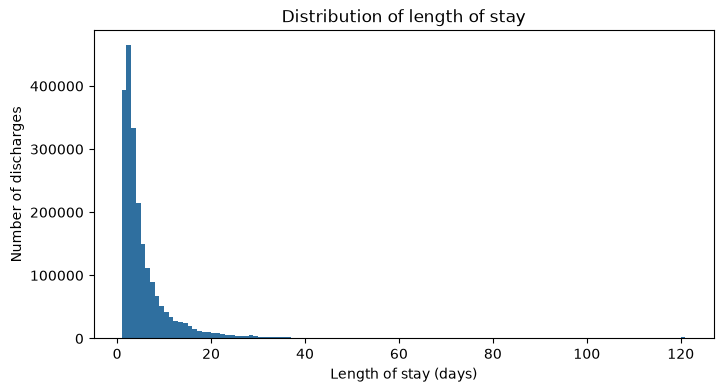

In [20]:
df_eda["los"].plot(kind="hist", bins=range(1, 122), figsize=(8, 4), color="#2f6f9f")
plt.xlabel("Length of stay (days)")
plt.ylabel("Number of discharges")
plt.title("Distribution of length of stay")
plt.show()

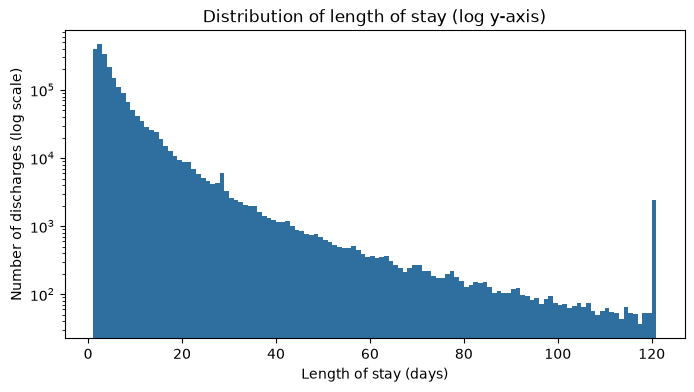

In [21]:
df_eda["los"].plot(kind="hist", bins=range(1, 122), figsize=(8, 4), color="#2f6f9f", logy=True)
plt.xlabel("Length of stay (days)")
plt.ylabel("Number of discharges (log scale)")
plt.title("Distribution of length of stay (log y-axis)")
plt.show()

**Target distribution (`los`)**
- `length_of_stay` contains one non-numeric token, `"120+"`, on 2,404 rows. SPARCS reports stays of 120 days or more in this bucket, so the target is right-censored at 120 and no plain "120" exists in the source. The token is converted to 120 in the numeric target `los`; these rows are identifiable as `los == 120`, so no separate flag is kept.
- `los` ranges from 1 to 120 days with a median of 3 and a mean of 5.81. There are no zero-day stays.
- The distribution is strongly right-skewed.
- On the linear plot the tail beyond about 30 days is barely visible, so the bulk of the data sits under 20 days.
- Because of the heavy right tail, a log transform is a candidate. 

## 4. Column decisions

### 4.1 Constant column

In [22]:
print(df_raw["discharge_year"].unique())

<ArrowStringArray>
['2024']
Length: 1, dtype: str


- `discharge_year` only has one value (2024), so it can't help explain length of stay. We can directly drop it.

### 4.2 Data leakage: columns dropped by definition

The goal is to predict length of stay for a patient who has just been admitted, so a column that describes the completed stay cannot be a feature.

- `patient_disposition` records where the patient went after leaving the hospital (home, transferred, left against medical advice, expired, etc.). It is a discharge outcome and is not known at admission.
- `total_charges` is the total amount billed for the whole stay, so it grows with every extra day in the hospital.
- `total_costs` is the total cost of the whole stay and works the same way.

(Both are essentially a function of length of stay, so a model using them would just be reading the answer off.)

### 4.3 Redundant info pairs

In [23]:
pairs = [("apr_severity_of_illness_code", "apr_severity_of_illness"),
         ("apr_mdc_code", "apr_mdc_description"),
         ("apr_drg_code", "apr_drg_description"),
         ("ccsr_diagnosis_code", "ccsr_diagnosis_description"),
         ("ccsr_procedure_code", "ccsr_procedure_description")]

for code_col, desc_col in pairs:
    a = df_raw.groupby(code_col)[desc_col].nunique().max()
    b = df_raw.groupby(desc_col)[code_col].nunique().max()
    # rows where exactly one of the two is missing (nunique silently ignores these)
    mismatch = (df_raw[code_col].isna() != df_raw[desc_col].isna()).sum()
    print(f"{code_col:30s} desc per code: {a}   code per desc: {b}   missing mismatch: {mismatch}")

apr_severity_of_illness_code   desc per code: 1   code per desc: 1   missing mismatch: 0
apr_mdc_code                   desc per code: 1   code per desc: 1   missing mismatch: 0
apr_drg_code                   desc per code: 1   code per desc: 1   missing mismatch: 0
ccsr_diagnosis_code            desc per code: 1   code per desc: 1   missing mismatch: 0
ccsr_procedure_code            desc per code: 1   code per desc: 1   missing mismatch: 0


- `apr_severity_of_illness`, `apr_mdc_description`, `apr_drg_description`, `ccsr_diagnosis_description` and `ccsr_procedure_description` map one to one with their codes. The description columns carry no extra information and will be dropped; the code columns are kept.

## 5. Row decision: redacted facility records

Notes in Website: Discharges that are identified as abortion will have some information redacted; PFI, Facility Name, Health Service Area, Hospital County, and Operating Certificate.

In [24]:
# Are the four facility fields missing on the same rows?
fac = ["permanent_facility_id", "operating_certificate_number",
       "hospital_county", "health_service_area"]

print("rows with all 4 missing:", df_eda[fac].isna().all(axis=1).sum())
print("rows with any of the 4 missing:", df_eda[fac].isna().any(axis=1).sum())  # if equal to the line above, the 4 columns miss on identical rows

# What does facility_name look like on those rows?
print(df_eda.loc[df_eda["permanent_facility_id"].isna(), "facility_name"].value_counts().head())

rows with all 4 missing: 5295
rows with any of the 4 missing: 5295
facility_name
Redacted for Confidentiality    5295
Name: count, dtype: int64


In [27]:
red = df_eda["permanent_facility_id"].isna()      # True for the redacted rows
print("redacted rows:", red.sum(), f"({red.mean()*100:.2f}%)\n")

# print("LOS redacted:\n", df_eda.loc[red, "los"].describe(percentiles=[.25, .5, .75, .95]).round(2))
# print("LOS others:\n",   df_eda.loc[~red, "los"].describe(percentiles=[.25, .5, .75, .95]).round(2))

redacted rows: 5295 (0.24%)



In [28]:
# What are they clinically? Top diagnosis codes among the redacted rows, with names looked up from df_raw
names = (df_raw[["ccsr_diagnosis_code", "ccsr_diagnosis_description"]]
         .drop_duplicates().set_index("ccsr_diagnosis_code")["ccsr_diagnosis_description"])
top = df_eda.loc[red, "ccsr_diagnosis_code"].value_counts(normalize=True).head(20).round(3)
pd.DataFrame({"share_of_redacted": top, "diagnosis": names.reindex(top.index).values})

,share_of_redacted,diagnosis
ccsr_diagnosis_code,,
PRG003,0.20,SPONTANEOUS ABORTION AND COMPLICATIONS OF SPON...
PRG005,0.20,ECTOPIC PREGNANCY AND COMPLICATIONS OF ECTOPIC...
PRG006,0.09,MOLAR PREGNANCY AND OTHER ABNORMAL PRODUCTS OF...
PRG004,0.06,INDUCED ABORTION AND COMPLICATIONS OF TERMINAT...
PNL001,0.05,LIVEBORN
INF002,0.03,SEPTICEMIA
MBD017,0.01,ALCOHOL-RELATED DISORDERS
MBD001,0.01,SCHIZOPHRENIA SPECTRUM AND OTHER PSYCHOTIC DIS...
PRG028,0.01,OTHER SPECIFIED COMPLICATIONS IN PREGNANCY


- All four facility fields are missing on the same 5,295 rows (0.24% of the data), and `facility_name` is "Redacted for Confidentiality" on every one of them.
- The SPARCS documentation states that discharges identified as abortion have PFI, facility name, health service area, hospital county and operating certificate redacted, so this is deliberate redaction and not random missingness.
- The four most common principal diagnoses among these rows are spontaneous abortion, ectopic pregnancy, molar pregnancy and induced abortion, which together make up about 55% of the redacted rows. The remaining rows have other principal diagnoses.
- Facility, county, health service area and certificate are identifiers, so imputing them (with the mode or any other value) would assign real patients to a hospital they were not treated in and create a false facility signal.
- The rows are a very small share of the data, so dropping them has negligible effect on the model. Facility is always known at admission in real use, so the model is not intended for discharges that the release redacts.

**Decision: drop the 5,295 rows with redacted facility information.**

In [29]:
df_nonredacted = df_eda[df_eda["permanent_facility_id"].notna()].copy()
print("rows before:", f"{len(df_eda):,}", "| after:", f"{len(df_nonredacted):,}",
      "| removed:", f"{len(df_eda) - len(df_nonredacted):,}")

rows before: 2,196,737 | after: 2,191,442 | removed: 5,295


## 6. Facility and geography hierarchy

### 6.1 Facility id and facility name

In [30]:
# Facility id <-> name mapping
# groupby id, count distinct names; max > 1 means at least one id has several names
print("max ids per name:", df_nonredacted.groupby("facility_name")["permanent_facility_id"].nunique().max())
print("max names per id:", df_nonredacted.groupby("permanent_facility_id")["facility_name"].nunique().max())

max ids per name: 2
max names per id: 1


In [31]:
ids_per_name = df_nonredacted.groupby("facility_name")["permanent_facility_id"].nunique()   # distinct ids per name
shared = ids_per_name[ids_per_name > 1]                                                    # names with more than one id
print(len(shared), "names are shared by more than one id")
print(shared)

3 names are shared by more than one id
facility_name
BRONXCARE HOSPITAL CENTER                                               2
THE UNIVERSITY OF VERMONT HEALTH NETWORK - ALICE HYDE MEDICAL CENTER    2
WYOMING COUNTY COMMUNITY HOSPITAL                                       2
Name: permanent_facility_id, dtype: int64


- Each `permanent_facility_id` maps to exactly one `facility_name` (max 1 name per id), but a `facility_name` can map to up to 2 IDs (max 2 ids per name). So the name is fully determined by the ID, while the ID is not determined by the name.
- Three names are shared by two IDs: BRONXCARE HOSPITAL CENTER, THE UNIVERSITY OF VERMONT HEALTH NETWORK - ALICE HYDE MEDICAL CENTER and WYOMING COUNTY COMMUNITY HOSPITAL.
- `facility_name` adds nothing beyond `permanent_facility_id` and can be ambiguous, so it is dropped.

### 6.2 Operating certificate and facility id

In [32]:
# Direction A: how many different certificates does each facility id sit under?
certs_per_id = df_nonredacted.groupby("permanent_facility_id")["operating_certificate_number"].nunique()
print("max certificates per id:", certs_per_id.max())

# Direction B: how many different ids sit under each certificate?
ids_per_cert = df_nonredacted.groupby("operating_certificate_number")["permanent_facility_id"].nunique()
print("max ids per certificate:", ids_per_cert.max())
print("certificates covering more than one id:", (ids_per_cert > 1).sum(), "of", len(ids_per_cert))

max certificates per id: 1
max ids per certificate: 8
certificates covering more than one id: 31 of 158


- Every facility id belongs to exactly one certificate (max 1 certificate per id), and 31 of 158 certificates cover more than one facility id (up to 8). The certificate is therefore the coarser level, with facility ids nested under it.
- `operating_certificate_number`, `hospital_county` and `health_service_area` are coarser groupings of the facility. They are kept as candidates.

## 7. Feature reviews

### 7.1 ZIP code

Notes in Website: Patient zip code is limited to the first three digits. However, in cases where the population size for the zip code is less than 20,000, if the cell size on patient classification strata is less than 10, or if the record is an abortion, then the zip code is blank. The code “OOS” indicates Out of State zip codes.

In [33]:
print(df_nonredacted["zip_code"].value_counts(dropna=False))
print("\nmissing zip:", df_nonredacted["zip_code"].isna().sum(),
      f"({df_nonredacted['zip_code'].isna().mean()*100:.2f}%)")

zip_code
112    266231
104    207886
117    188654
100    152265
113    111758
114     87826
115     87740
OOS     65078
109     59826
105     57920
142     57447
103     57402
146     55504
125     43969
140     38472
NaN     36677
130     36275
119     34249
145     30436
120     29842
144     28047
107     27464
110     26687
121     26238
132     24260
136     22305
128     22189
148     19931
111     19195
134     18295
116     17864
124     17805
141     17459
131     16970
123     15516
122     15392
147     15298
133     14055
137     12948
138     12383
127     11973
129     11909
126     11259
106      9321
135      8975
118      8527
108      8515
139      8326
143      6940
149      5053
101      4886
Name: count, dtype: int64

missing zip: 36677 (1.67%)


In [34]:
# Preview of the planned labelling (applied for real in section 11): missing zip becomes an explicit level, OOS stays as it is
zip_preview = df_nonredacted["zip_code"].fillna("Suppressed")
print(zip_preview.isna().sum())
print(zip_preview.isin(["OOS", "Suppressed"]).sum(), "rows are OOS or Suppressed")
print(zip_preview.value_counts().head(8))

0
101755 rows are OOS or Suppressed
zip_code
112    266231
104    207886
117    188654
100    152265
113    111758
114     87826
115     87740
OOS     65078
Name: count, dtype: int64


- `zip_code` has two special cases. `OOS` (out of state) is a valid value and is kept. Missing values are deliberate suppression by SPARCS (small population, small cell size, or abortion), so they are not imputed. They are encoded as a separate `"Suppressed"` level, kept distinct from `OOS` because they mean different things.

### 7.2 Payment typology 1

`payment_typology_1` is the source of payment for the discharge: the primary payer expected to pay for the stay (typologies 2 and 3 are the secondary and tertiary payers).

In [35]:
p1 = df_nonredacted["payment_typology_1"]

# All 9 levels plus missing, with counts
vc = p1.value_counts(dropna=False)
print(pd.DataFrame({"rows": vc, "pct": (vc / len(p1) * 100).round(3)}).to_string(), "\n")

                             rows   pct
payment_typology_1                     
Medicare                   928688 42.38
Medicaid                   632965 28.88
Private Health Insurance   316720 14.45
Blue Cross/Blue Shield     203582  9.29
Self-Pay                    34611  1.58
Managed Care, Unspecified   30237  1.38
Miscellaneous/Other         21724  0.99
Federal/State/Local/VA      21068  0.96
Department of Corrections    1620  0.07
NaN                           227  0.01 



In [36]:
# Do the missing rows have a payer in slot 2 or 3? (a second payer with no first payer is odd)
m = df_nonredacted[p1.isna()]
print("missing typ1 but typ2 present:", m["payment_typology_2"].notna().sum())
print("missing typ1 but typ3 present:", m["payment_typology_3"].notna().sum(), "\n")

print(m["payment_typology_2"].value_counts(), "\n")
print(m["payment_typology_3"].value_counts())

missing typ1 but typ2 present: 80
missing typ1 but typ3 present: 3 

payment_typology_2
Medicaid                    65
Medicare                     8
Blue Cross/Blue Shield       3
Federal/State/Local/VA       3
Private Health Insurance     1
Name: count, dtype: int64 

payment_typology_3
Medicaid    3
Name: count, dtype: int64


- `payment_typology_1` has 9 levels, led by Medicare (42.38%), Medicaid (28.88%) and Private Health Insurance (14.45%), and 227 missing values (0.01%).
- Of the missing rows, 80 have a second payer (65 Medicaid, 8 Medicare, 3 Blue Cross/Blue Shield, 3 Federal/State/Local/VA, 1 Private) and 3 have a third payer (all Medicaid). The first payer was therefore left unrecorded while later slots were filled. 
- These rows are labelled `"Not recorded"` and kept (0.01% of the data). 
- It is treated as known at admission because insurance is normally collected at registration. 

### 7.3 Payment typology 2 and 3

In [37]:
for col in ["payment_typology_2", "payment_typology_3"]:
    s = df_nonredacted[col]
    vc = s.value_counts(dropna=False)
    print(f"=== {col} ===")
    print(pd.DataFrame({"rows": vc, "pct": (vc / len(s) * 100).round(3)}).to_string(), "\n")

=== payment_typology_2 ===
                              rows   pct
payment_typology_2                      
NaN                        1200668 54.79
Medicaid                    420069 19.17
Medicare                    168479  7.69
Private Health Insurance    153439  7.00
Self-Pay                    121094  5.53
Blue Cross/Blue Shield      105813  4.83
Federal/State/Local/VA       13169  0.60
Managed Care, Unspecified     5525  0.25
Miscellaneous/Other           3073  0.14
Department of Corrections      113  0.01 

=== payment_typology_3 ===
                              rows   pct
payment_typology_3                      
NaN                        1951791 89.06
Self-Pay                    123957  5.66
Medicaid                     67424  3.08
Private Health Insurance     19797  0.90
Blue Cross/Blue Shield       13843  0.63
Medicare                     11793  0.54
Federal/State/Local/VA        2060  0.09
Managed Care, Unspecified      470  0.02
Miscellaneous/Other            288  0.01
D

In [38]:
# Logical consistency: a later payer filled while an earlier slot is empty
p1_label = df_nonredacted["payment_typology_1"].fillna("Not recorded")
p2, p3 = df_nonredacted["payment_typology_2"], df_nonredacted["payment_typology_3"]
print("typ3 present but typ2 missing:", (p3.notna() & p2.isna()).sum())
print("typ2 present but typ1 'Not recorded':", (p2.notna() & p1_label.eq("Not recorded")).sum())

typ3 present but typ2 missing: 6
typ2 present but typ1 'Not recorded': 80


- `payment_typology_2` is missing on 54.79% of rows and `payment_typology_3` on 89.06%. Missing here most likely means the patient had no additional payer, so it is structural and not a data-quality problem.
- The missing values are not imputed. They will be labelled `"No second payer"` and `"No third payer"`.
- 80 rows have a second payer with the primary payer not recorded, and 6 rows have a third payer with no second payer.

### 7.4 Type of admission and the emergency department indicator

In [39]:
t = df_nonredacted["type_of_admission"]

# All levels with counts and shares
vc = t.value_counts(dropna=False)
print(pd.DataFrame({"rows": vc, "pct": (vc / len(t) * 100).round(3)}).to_string(), "\n")

# Does it agree with the emergency department indicator?
# Share within each admission type (each row sums to 100)
ed = pd.crosstab(t, df_nonredacted["emergency_department_indicator"], normalize="index", dropna=False) * 100
print(ed.round(2))

                      rows   pct
type_of_admission               
Emergency          1456451 66.46
Elective            355154 16.21
Newborn             197959  9.03
Urgent              168194  7.67
Trauma               10038  0.46
Not Available         3646  0.17 

emergency_department_indicator     N     Y
type_of_admission                         
Elective                       97.63  2.37
Emergency                       8.84 91.16
Newborn                        99.91  0.09
Not Available                  89.11 10.89
Trauma                          6.48 93.52
Urgent                         83.67 16.33


- Six levels: Emergency (66.46%), Elective (16.21%), Newborn (9.03%), Urgent (7.68%), Trauma (0.46%) and Not Available (0.17%, 3,646 rows). `Not Available` is a placeholder for an unknown admission type and is kept as its own level, since the true type cannot be recovered.
- Admission type and `emergency_department_indicator` overlap but are not redundant. The share passing through the ED is 93.52% for Trauma and 91.16% for Emergency, but only 16.33% for Urgent and 2.37% for Elective. 

## 8. Birth weight and the newborn cohort

In [40]:
t = df_nonredacted["type_of_admission"]

# Label the flag so the missing rows appear by name
has_w = (df_nonredacted["birth_weight"].isna()
         .map({True: "no_weight (NaN)", False: "has_weight"})
         .rename("birth_weight"))

# Overall: share of rows with and without a birth weight
overall = has_w.value_counts()
print(pd.DataFrame({"rows": overall, "pct": (overall / len(has_w) * 100).round(2)}), "\n")

# Raw counts per admission type, with totals
print(pd.crosstab(t, has_w, margins=True, margins_name="Total", dropna=False), "\n")

# Row-wise: within each admission type, % with / without a weight (each row sums to 100)
print((pd.crosstab(t, has_w, normalize="index", dropna=False) * 100).round(2), "\n")

# Column-wise: of all rows with a weight (and of all without), the share of each admission type
print((pd.crosstab(t, has_w, normalize="columns", margins=True, margins_name="Total", dropna=False) * 100).round(2))

                    rows   pct
birth_weight                  
no_weight (NaN)  1983915 90.53
has_weight        207527  9.47 

birth_weight       has_weight  no_weight (NaN)    Total
type_of_admission                                      
Elective                  878           354276   355154
Emergency                6269          1450182  1456451
Newborn                197902               57   197959
Not Available              31             3615     3646
Trauma                     18            10020    10038
Urgent                   2429           165765   168194
Total                  207527          1983915  2191442 

birth_weight       has_weight  no_weight (NaN)
type_of_admission                             
Elective                 0.25            99.75
Emergency                0.43            99.57
Newborn                 99.97             0.03
Not Available            0.85            99.15
Trauma                   0.18            99.82
Urgent                   1.44          

Observations
- `Newborn` admissions are 9.03% of the data. `birth_weight` is recorded for 9.47% of all rows and is blank for 90.53%.
- `Birth weight` is recorded for 99.97% of Newborn admissions, and 95.36% of all recorded weights sit on Newborn admissions.
- So birth weight does not apply to non-newborn patients in general.

Decision
- `Newborn` admissions are excluded from the main model, and `birth_weight` is dropped from it. Outside the newborn group the column is almost entirely empty and carries no usable information.

Reasoning
- **Different problem from the project goal.** The goal is to predict the stay of a patient admitted with a condition, based on the initial diagnosis. A newborn admission is a birth in the hospital, which is a different process, so these records are out of scope for that question.
- **Same columns, different meaning.** Birth weight is informative only within newborns and irrelevant to everyone else. Keeping both groups would force one model to learn two separate regimes from a single feature set.

In [41]:
is_nb = df_nonredacted["type_of_admission"].eq("Newborn")

df_main = df_nonredacted[~is_nb].copy()      # main cohort (still all columns; columns are dropped in section 11)
df_newborn = df_nonredacted[is_nb].copy()    # kept aside for a possible second model

print("main cohort:", f"{len(df_main):,}", "| newborn cohort:", f"{len(df_newborn):,}")   # 1,993,483 and 197,959
print(df_main["type_of_admission"].value_counts())

main cohort: 1,993,483 | newborn cohort: 197,959
type_of_admission
Emergency        1456451
Elective          355154
Urgent            168194
Trauma             10038
Not Available       3646
Name: count, dtype: int64


## 9. Gender, race and ethnicity

In [42]:
demo = ["gender", "race", "ethnicity"]

# Levels, counts and shares, with missing shown explicitly
for c in demo:
    vc = df_main[c].value_counts(dropna=False)
    print(f"=== {c} ({df_main[c].nunique()} levels) ===")
    print(pd.DataFrame({"rows": vc, "pct": (vc / len(df_main) * 100).round(2)}).to_string(), "\n")

=== gender (3 levels) ===
           rows   pct
gender               
F       1094776 54.92
M        898586 45.08
U           121  0.01 

=== race (4 levels) ===
                           rows   pct
race                                 
White                   1057481 53.05
Other Race               536960 26.94
Black/African American   370947 18.61
Multi-racial              28095  1.41 

=== ethnicity (4 levels) ===
                      rows   pct
ethnicity                       
Not Span/Hispanic  1423788 71.42
Spanish/Hispanic    326479 16.38
Unknown             240857 12.08
Multi-ethnic          2359  0.12 



- No missing values in any of the three. Unknown values appear as explicit levels: `gender` `U` (121 rows, 0.01%) and `ethnicity` `Unknown` (240,857 rows, 12.08%), and these are kept as it is.

## 10. Still to review

In [44]:
# Severity, mortality and medical/surgical levels, and the procedure column
for c in ["apr_severity_of_illness_code", "apr_risk_of_mortality", "apr_medical_surgical"]:
    vc = df_main[c].value_counts(dropna=False)
    print(f"=== {c} ===")
    print(pd.DataFrame({"rows": vc, "pct": (vc / len(df_main) * 100).round(3)}).to_string(), "\n")

proc_missing = df_main["ccsr_procedure_code"].isna()
print("ccsr_procedure_code missing:", f"{proc_missing.sum():,}", f"({proc_missing.mean()*100:.2f}%)")

=== apr_severity_of_illness_code ===
                                rows   pct
apr_severity_of_illness_code              
2                             774421 38.85
3                             555289 27.86
1                             482205 24.19
4                             181187  9.09
0                                381  0.02 

=== apr_risk_of_mortality ===
                         rows   pct
apr_risk_of_mortality              
Minor                  914329 45.87
Moderate               470700 23.61
Major                  437879 21.97
Extreme                170194  8.54
Undetermined              381  0.02 

=== apr_medical_surgical ===
                         rows   pct
apr_medical_surgical               
Medical               1485947 74.54
Surgical               507155 25.44
Not Applicable            381  0.02 

ccsr_procedure_code missing: 581,407 (29.17%)


In [45]:
sev0 = df_main["apr_severity_of_illness_code"].eq("0")        # codes are stored as strings

# 1. Are the three flags the same rows?
rom_u = df_main["apr_risk_of_mortality"].eq("Undetermined")
med_na = df_main["apr_medical_surgical"].eq("Not Applicable")
print("severity 0:", sev0.sum(), "| mortality Undetermined:", rom_u.sum(), "| medical/surgical N/A:", med_na.sum())
print("all three together:", (sev0 & rom_u & med_na).sum(), "| any of the three:", (sev0 | rom_u | med_na).sum(), "\n")

odd = df_main[sev0]

# 2. What are they? DRG, MDC and diagnosis, with names looked up from df_raw
def top_named(col, name_col, n=6):
    names = df_raw[[col, name_col]].drop_duplicates().set_index(col)[name_col]
    top = odd[col].value_counts(normalize=True).head(n).round(3)
    return pd.DataFrame({"share": top, "name": names.reindex(top.index).values})

print(top_named("apr_drg_code", "apr_drg_description"), "\n")
print(top_named("apr_mdc_code", "apr_mdc_description"), "\n")
print(top_named("ccsr_diagnosis_code", "ccsr_diagnosis_description"), "\n")

severity 0: 381 | mortality Undetermined: 381 | medical/surgical N/A: 381
all three together: 381 | any of the three: 381 

              share                                               name
apr_drg_code                                                          
955            0.89  PRINCIPAL DIAGNOSIS INVALID AS DISCHARGE DIAGN...
956            0.12                                        UNGROUPABLE 

              share                                               name
apr_mdc_code                                                          
14             0.88           PREGNANCY, CHILDBIRTH AND THE PUERPERIUM
00             0.12                                            PRE MDC
15             0.01  NEWBORNS AND OTHER NEONATES WITH CONDTN ORIG I... 

                     share                                               name
ccsr_diagnosis_code                                                          
PRG023                0.46          COMPLICATIONS SPECIFIED DURING CHILDBIRTH

**Severity `0`, mortality `Undetermined`, medical/surgical `Not Applicable`**
- The same 381 rows (0.02% of the main cohort) have severity code `0`, risk of mortality `Undetermined` and medical/surgical `Not Applicable`.
- Severity and risk of mortality are ordered scales, and these values are not a level on either. They would corrupt the ordering if encoded, and cannot be imputed, so the 381 rows are dropped.

## ccsr code

In [51]:
proc_missing = df_main["ccsr_procedure_code"].isna().rename("procedure_missing")

# 1. Missing procedure by medical/surgical class (counts with totals)
print(pd.crosstab(df_main["apr_medical_surgical"], proc_missing, margins=True, margins_name="Total"), "\n")

# 2. Same, as % within each class (each row sums to 100)
print((pd.crosstab(df_main["apr_medical_surgical"], proc_missing, normalize="index") * 100).round(2), "\n")

procedure_missing       False    True    Total
apr_medical_surgical                          
Medical                904659  581288  1485947
Not Applicable            262     119      381
Surgical               507155       0   507155
Total                 1412076  581407  1993483 

procedure_missing     False  True 
apr_medical_surgical              
Medical               60.88  39.12
Not Applicable        68.77  31.23
Surgical             100.00   0.00 



**`ccsr_procedure_code`**
- The missing values are almost all on medical stays and none are on surgical stays, so a blank means no procedure was recorded for the stay, not lost data.
-  It will be labelled `"No procedure recorded"` and kept as its own level. (381 rows of not applicable are already getting dropped)

## 11. Build `df_clean`

Every decision above is applied here in one place, starting from `df_main`. The earlier frames are not modified.

**Columns excluded from the admission-time model**
Page 53 (Chapter 3) states it directly:

- The 3M APR-DRG Methodology Overview (HCUP, p. 53) states that the base APR DRG, severity of illness subclass and risk of mortality subclass "represent the patient's condition at the time of discharge and include the impact of conditions that developed during the hospital stay". The admission version needs a present-on-admission indicator and procedure dates, which the public SPARCS file does not contain.
- `apr_severity_of_illness_code`, `apr_risk_of_mortality` and `apr_drg_code` are therefore dropped. 

In [87]:
COLS_TO_DROP = [
    # constant
    "discharge_year",
    # leakage: describe the completed stay
    "patient_disposition", "total_charges", "total_costs",
    # redundant: determined by permanent_facility_id
    "facility_name",
    # redundant: 1:1 duplicates of their code columns
    "apr_severity_of_illness", "apr_mdc_description", "apr_drg_description",
    "ccsr_diagnosis_description", "ccsr_procedure_description",
    # replaced by the numeric target `los`
    "length_of_stay",
    # structural blank outside the newborn cohort
    "birth_weight",
    # discharge-time grouper outputs (HCUP APR-DRG overview, p. 53)
    "apr_severity_of_illness_code", "apr_risk_of_mortality", "apr_drg_code",
]

# rows the APR-DRG grouper could not classify (severity 0 / mortality Undetermined / medical-surgical Not Applicable)
ungroupable = df_main["apr_severity_of_illness_code"].eq("0")

df_clean = (
    df_main[~ungroupable]
    .drop(columns=COLS_TO_DROP)
    .assign(
        zip_code=lambda d: d["zip_code"].fillna("Suppressed"),
        payment_typology_1=lambda d: d["payment_typology_1"].fillna("Not recorded"),
        payment_typology_2=lambda d: d["payment_typology_2"].fillna("No second payer"),
        payment_typology_3=lambda d: d["payment_typology_3"].fillna("No third payer"),
        ccsr_procedure_code=lambda d: d["ccsr_procedure_code"].fillna("No procedure recorded")
    )
    .reset_index(drop=True)
)

In [89]:
# Row flow: raw -> clean
print(f"df_raw          : {len(df_raw):,}")
print(f"df_nonredacted  : {len(df_nonredacted):,}")
print(f"df_main         : {len(df_main):,}")
print(f"df_clean        : {len(df_clean):,}")
print("shape:", df_clean.shape)

# Basic checks
assert df_clean["permanent_facility_id"].notna().all()                     # no redacted facility records
assert not df_clean["type_of_admission"].eq("Newborn").any()               # no newborn admissions
assert not any(c in df_clean.columns for c in COLS_TO_DROP)                # dropped columns are gone
assert df_clean["los"].between(1, 120).all()                               # target in the expected range
assert df_clean.isna().sum().sum() == 0                                    # no missing values left

print("\nall checks passed")
print("columns:", df_clean.columns.tolist())

df_raw          : 2,196,737
df_nonredacted  : 2,191,442
df_main         : 1,993,483
df_clean        : 1,993,102
shape: (1993102, 19)

all checks passed
columns: ['health_service_area', 'hospital_county', 'operating_certificate_number', 'permanent_facility_id', 'age_group', 'zip_code', 'gender', 'race', 'ethnicity', 'type_of_admission', 'ccsr_diagnosis_code', 'apr_mdc_code', 'apr_medical_surgical', 'payment_typology_1', 'emergency_department_indicator', 'ccsr_procedure_code', 'payment_typology_2', 'payment_typology_3', 'los']


In [90]:
# Save the cleaned main cohort
OUT_PATH = Path("../data/processed/sparcs_2024_main_clean.parquet")
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
df_clean.to_parquet(OUT_PATH)
print("saved:", OUT_PATH)

saved: ../data/processed/sparcs_2024_main_clean.parquet


## Univariate Analysis

In [91]:
# Cell 1: the target on the final cohort

print(df_clean["los"].describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(2))
print("mean:", round(df_clean["los"].mean(), 2),
      "| median:", df_clean["los"].median(),
      "| skew:", round(df_clean["los"].skew(), 2))

count   1,993,102.00
mean            6.04
std             8.84
min             1.00
25%             2.00
50%             3.00
75%             7.00
90%            13.00
95%            19.00
99%            42.00
max           120.00
Name: los, dtype: float64
mean: 6.04 | median: 3.0 | skew: 5.97


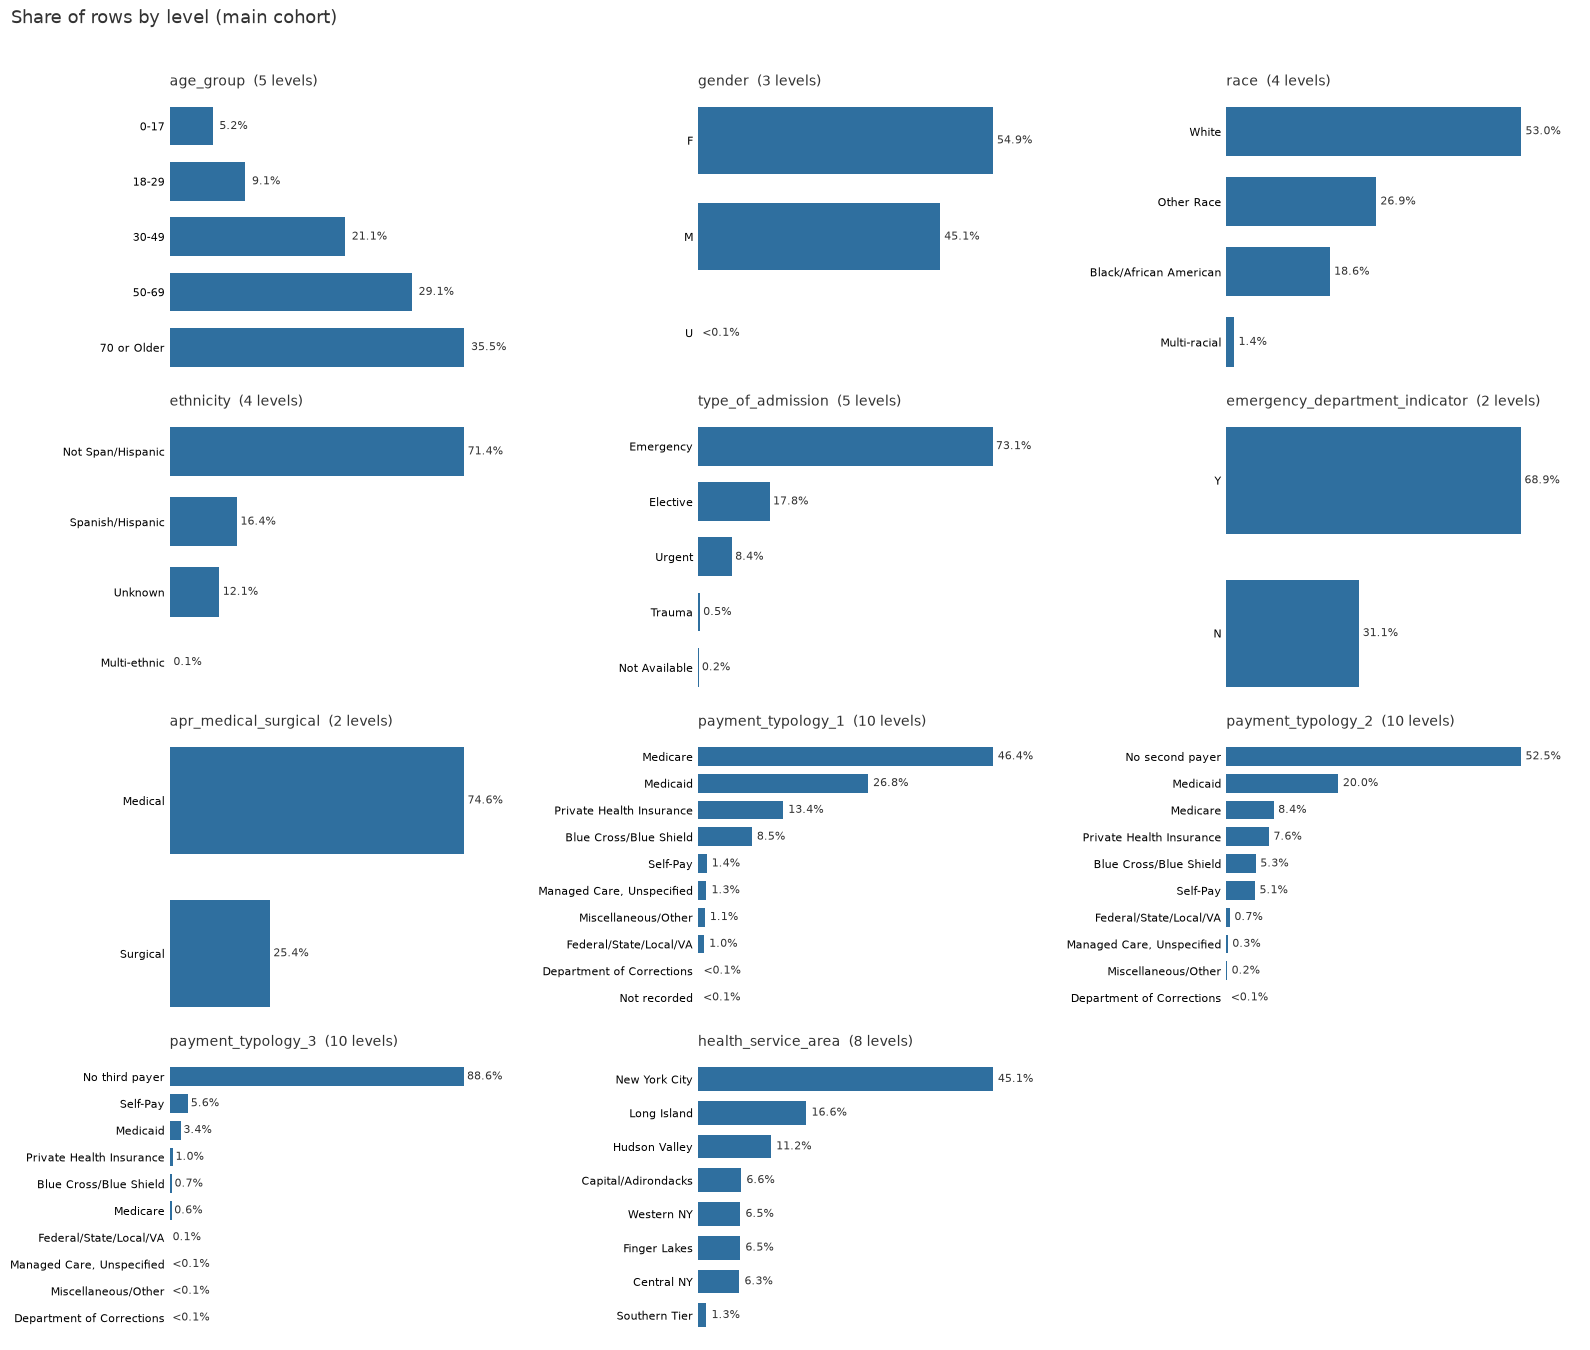

In [92]:
BLUE, INK = "#2f6f9f", "#333333"

def share_bar(ax, s, order=None):
    pct = s.value_counts(normalize=True) * 100
    if order is not None:
        pct = pct.reindex(order)                  # real order for ordinal columns
    pct = pct.iloc[::-1]                          # barh draws bottom-up, so the first level ends on top
    ax.barh(pct.index.astype(str), pct.values, color=BLUE, height=0.7)
    for y, v in enumerate(pct.values):
        ax.text(v + 0.8, y, f"{v:.1f}%" if v >= 0.1 else "<0.1%", va="center", fontsize=8, color=INK)
    ax.set_title(f"{s.name}  ({s.nunique()} levels)", loc="left", fontsize=10, color=INK)
    ax.set_xlim(0, pct.values.max() * 1.2)
    ax.set_xticks([])                             # values are labelled directly
    ax.tick_params(axis="y", labelsize=8, length=0)
    ax.spines[["top", "right", "bottom", "left"]].set_visible(False)

ORDER = {
    "age_group": ["0-17", "18-29", "30-49", "50-69", "70 or Older"]
}
LOW_CARD = ["age_group", "gender", "race", "ethnicity", "type_of_admission",
            "emergency_department_indicator", "apr_medical_surgical",
            "payment_typology_1", "payment_typology_2", "payment_typology_3",
            "health_service_area"]

fig, axes = plt.subplots(5, 3, figsize=(16, 17))
for ax, col in zip(axes.flat, LOW_CARD):
    share_bar(ax, df_clean[col], ORDER.get(col))
for ax in axes.flat[len(LOW_CARD):]:
    ax.set_visible(False)                         # unused panels
fig.suptitle("Share of rows by level (main cohort)", x=0.01, ha="left", fontsize=13, color=INK)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Univariate distributions (main cohort)**
- The population is older and mostly emergency admissions: 35.5% are 70 or older and 29.1% are 50-69, while 0-17 is 5.2%. Emergency is 73.1% of admissions, 68.9% pass through the ED, and 74.6% are medical stays.
- Medicare (46.4%) and Medicaid (26.8%) dominate the primary payer. Just over half have no second payer (52.5%), and 88.6% have no third payer.- Geography is New York City heavy: 45.1% of discharges are in the NYC health service area, followed by Long Island (16.6%) and Hudson Valley (11.2%). Southern Tier is 1.3%.

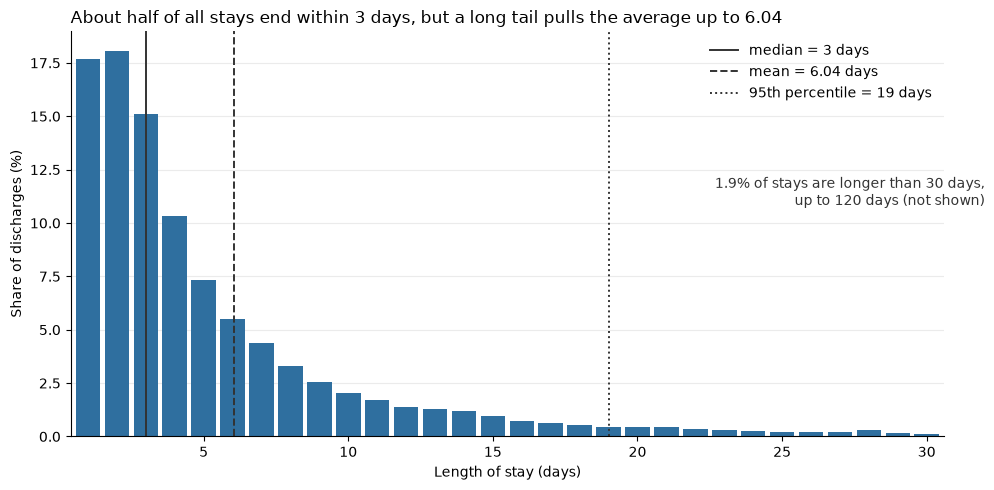

In [93]:
los = df_clean["los"]
median, mean, p95 = los.median(), los.mean(), los.quantile(0.95)
share_long = (los > 30).mean() * 100

pct = los.value_counts(normalize=True).sort_index() * 100     # % of discharges at each day count
body = pct.loc[1:30]                                          # 1 to 30 days holds ~98% of stays

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(body.index, body.values, color="#2f6f9f", width=0.85)

# three reference lines, told apart by line style and named in the legend
ax.axvline(median, color="#333333", lw=1.4, ls="-",  label=f"median = {median:.0f} days")
ax.axvline(mean,   color="#333333", lw=1.4, ls="--", label=f"mean = {mean:.2f} days")
ax.axvline(p95,    color="#333333", lw=1.4, ls=":",  label=f"95th percentile = {p95:.0f} days")
ax.legend(loc="upper right", frameon=False, fontsize=10)

# say what the axis cut hides
ax.text(32, body.max() * 0.60,
        f"{share_long:.1f}% of stays are longer than 30 days,\nup to {los.max()} days (not shown)",
        ha="right", fontsize=10, color="#333333")

ax.set_xlim(0.4, 30.6)
ax.set_xlabel("Length of stay (days)")
ax.set_ylabel("Share of discharges (%)")
ax.set_title(f"About half of all stays end within {median:.0f} days, "
             f"but a long tail pulls the average up to {mean:.2f}", loc="left", fontsize=12)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Length of stay (main cohort)**
- Stays are short: about half of all discharges end within 3 days (17.7% at 1 day, 18.1% at 2 days, 15.1% at 3 days).
- The distribution is strongly right-skewed. The mean (6.04 days) is about twice the median (3 days), the 95th percentile is 19 days, and 1.9% of stays are longer than 30 days, up to the 120-day cap.

### Bivariate analysis

### Age VS LOS

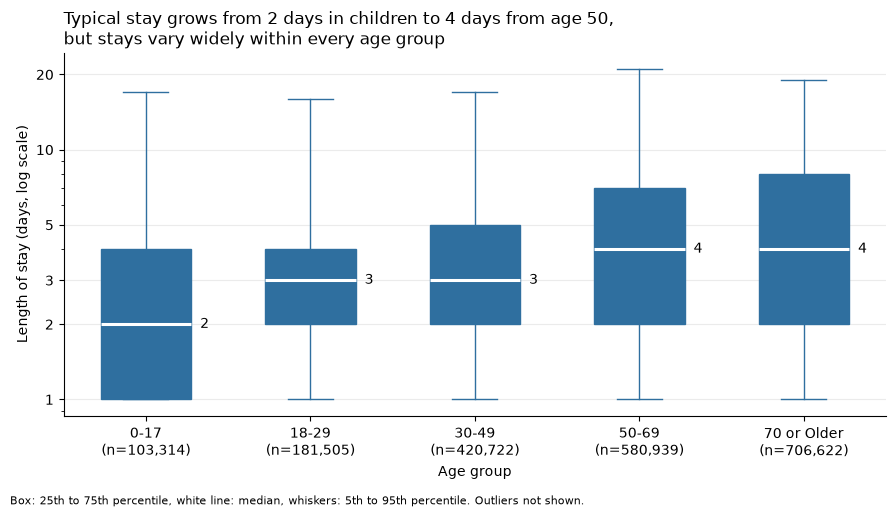

In [94]:
age_order = ["0-17", "18-29", "30-49", "50-69", "70 or Older"]
groups = [df_clean.loc[df_clean["age_group"] == a, "los"].values for a in age_order]
counts = [len(g) for g in groups]

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(groups, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.55,
           medianprops=dict(color="white", linewidth=2.2),
           boxprops=dict(facecolor="#2f6f9f", edgecolor="#2f6f9f"),
           whiskerprops=dict(color="#2f6f9f"), capprops=dict(color="#2f6f9f"))

ax.set_yscale("log")                                   # LOS is heavily right-skewed
ax.set_yticks([1, 2, 3, 5, 10, 20])
ax.set_yticklabels([1, 2, 3, 5, 10, 20])
ax.set_xticklabels([f"{a}\n(n={n:,})" for a, n in zip(age_order, counts)])

for i, g in enumerate(groups, start=1):                # label each median directly
    m = pd.Series(g).median()
    ax.text(i + 0.33, m, f"{m:.0f}", va="center", fontsize=10)

ax.set_xlabel("Age group")
ax.set_ylabel("Length of stay (days, log scale)")
ax.set_title("Typical stay grows from 2 days in children to 4 days from age 50,\n"
             "but stays vary widely within every age group", loc="left", fontsize=12)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.02, "Box: 25th to 75th percentile, white line: median, "
         "whiskers: 5th to 95th percentile. Outliers not shown.", fontsize=8)
plt.tight_layout()
plt.show()

**Age group against length of stay**
- The median stay rises with age: 2 days for 0-17, 3 days for 18-29 and 30-49, and 4 days for 50-69 and 70 or older. The 75th percentile also rises, from 4 days (0-17, 18-29) to 7 and 8 days (50-69, 70 or older).
- The spread within each age group is much larger than the difference between groups: every group runs from 1 day to about 16 to 21 days at the 95th percentile.
- Age is therefore informative about the typical stay but does not separate long stays from short ones by itself.

### Diagnosis VS LOS

top 15 diagnoses cover 33% of discharges


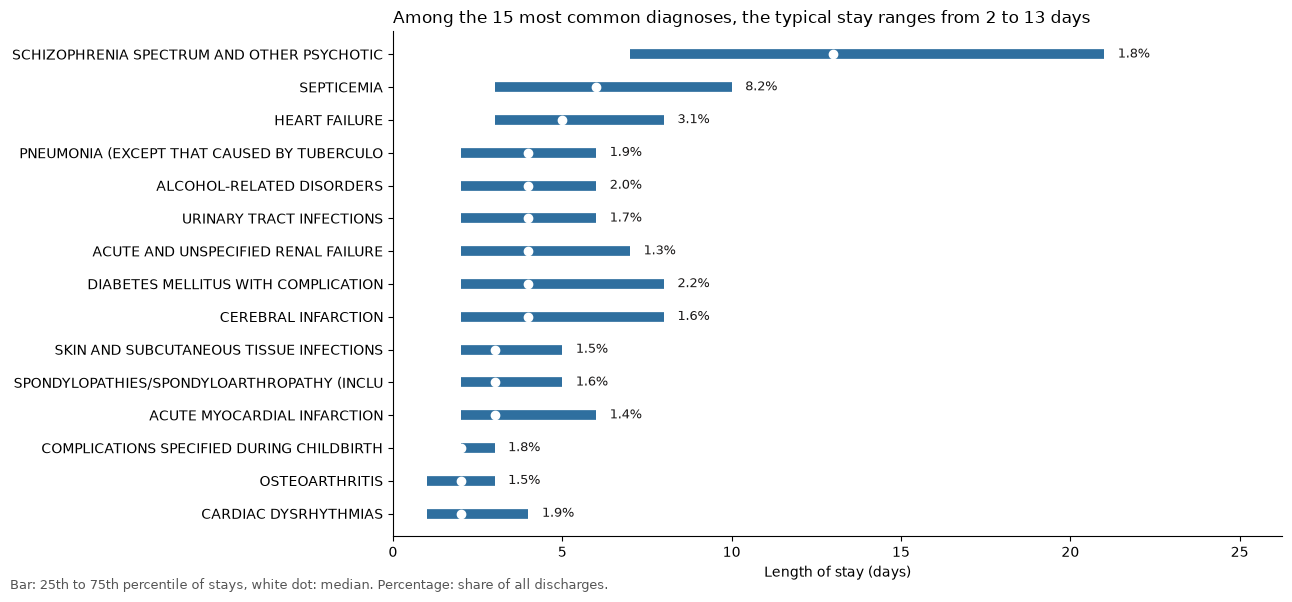

In [106]:
# Readable names for the diagnosis codes (the description column was dropped from df_clean)
names = df_raw.drop_duplicates("ccsr_diagnosis_code").set_index("ccsr_diagnosis_code")["ccsr_diagnosis_description"]

# The 15 most common diagnoses
top_codes = df_clean["ccsr_diagnosis_code"].value_counts().head(15).index
top = df_clean[df_clean["ccsr_diagnosis_code"].isin(top_codes)]
print(f"top 15 diagnoses cover {len(top) / len(df_clean):.0%} of discharges")

# Median and middle half of the stay for each, shortest median first
stats = top.groupby("ccsr_diagnosis_code")["los"].quantile([0.25, 0.5, 0.75]).unstack().sort_values(0.5)
counts = top["ccsr_diagnosis_code"].value_counts()

fig, ax = plt.subplots(figsize=(13, 6))
y = range(len(stats))
ax.hlines(y, stats[0.25], stats[0.75], color="#2f6f9f", lw=7)      # 25th to 75th percentile
ax.plot(stats[0.5], y, "o", color="white", ms=6)                   # median

n_total = len(df_clean)

for i, code in enumerate(stats.index):                             # share of all discharges, next to each bar
    share = counts[code] / n_total * 100
    ax.text(stats.loc[code, 0.75] + 0.4, i, f"{share:.1f}% ", va="center", fontsize=9, color="#1A1818")

ax.set_yticks(list(y))
ax.set_yticklabels([names[c][:42] for c in stats.index], fontsize=10)
ax.set_xlabel("Length of stay (days)")
ax.set_title(f"Among the 15 most common diagnoses, the typical stay ranges from "
             f"{stats[0.5].min():.0f} to {stats[0.5].max():.0f} days", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, stats[0.75].max() * 1.25)          # room after the longest bar and for the label

fig.text(0.01, 0.01, "Bar: 25th to 75th percentile of stays, white dot: median. "
         "Percentage: share of all discharges.", fontsize=9, color="#555555")
plt.tight_layout()
plt.show()


**Principal diagnosis against length of stay**
- The diagnosis strongly separates the typical stay: among the 15 most common diagnoses the median ranges from about 2 days to about 13 days.
- It also changes the spread: the middle half of schizophrenia stays runs from about 7 to 21 days, while for osteoarthritis and cardiac dysrhythmias it is only about 1 to 4 days.

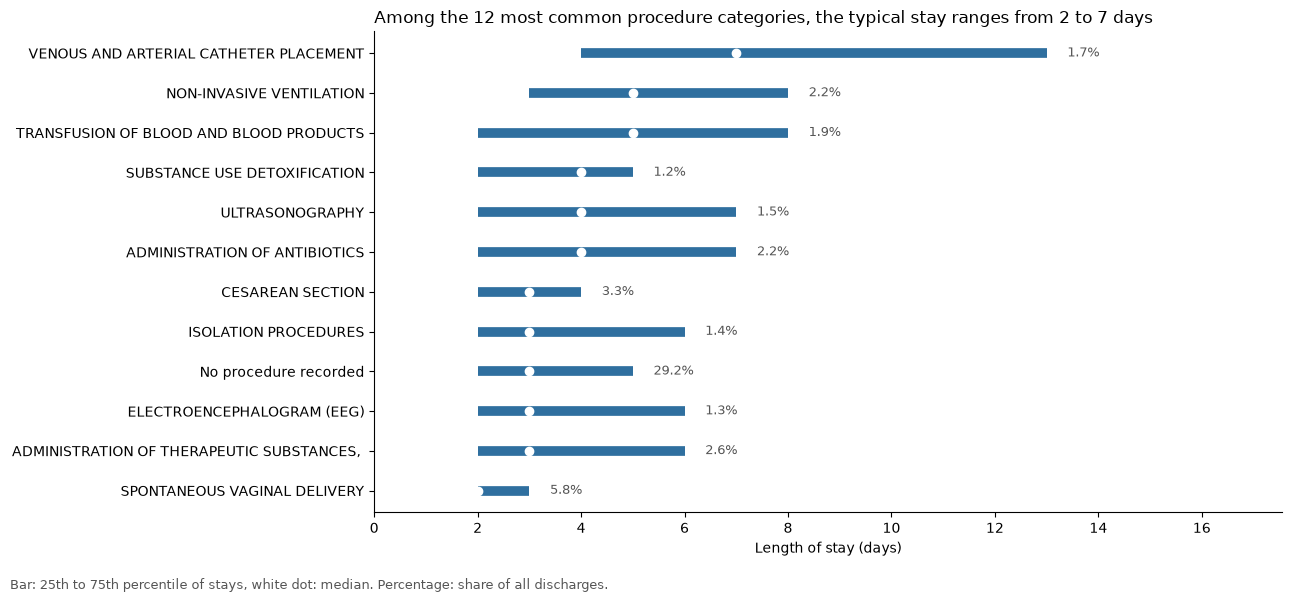

In [111]:
# Readable names for procedures (the description column was dropped from df_clean)
pnames = df_raw.drop_duplicates("ccsr_procedure_code").set_index("ccsr_procedure_code")["ccsr_procedure_description"]

# The 12 most common procedure categories, including "No procedure recorded"
top_codes = df_clean["ccsr_procedure_code"].value_counts().head(12).index
top = df_clean[df_clean["ccsr_procedure_code"].isin(top_codes)]

stats = top.groupby("ccsr_procedure_code")["los"].quantile([0.25, 0.5, 0.75]).unstack().sort_values(0.5)
share = top["ccsr_procedure_code"].value_counts() / len(df_clean) * 100

fig, ax = plt.subplots(figsize=(13, 6))
y = range(len(stats))
ax.hlines(y, stats[0.25], stats[0.75], color="#2f6f9f", lw=7)      # 25th to 75th percentile
ax.plot(stats[0.5], y, "o", color="white", ms=6)                   # median
for i, code in enumerate(stats.index):
    ax.text(stats.loc[code, 0.75] + 0.4, i, f"{share[code]:.1f}%", va="center", fontsize=9, color="#555555")

ax.set_yticks(list(y))
ax.set_yticklabels([pnames.get(c, c)[:42] for c in stats.index], fontsize=10)
ax.set_xlim(0, stats[0.75].max() * 1.35)
ax.set_xlabel("Length of stay (days)")
ax.set_title(f"Among the 12 most common procedure categories, the typical stay ranges from "
             f"{stats[0.5].min():.0f} to {stats[0.5].max():.0f} days", loc="left")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Bar: 25th to 75th percentile of stays, white dot: median. "
         "Percentage: share of all discharges.", fontsize=9, color="#555555")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


**Procedure category against length of stay**
- Among the 12 most common procedure categories the typical stay ranges from about 2 days (spontaneous vaginal delivery) to about 7 days (venous and arterial catheter placement, middle half 4 to 13 days). Catheter placement, non-invasive ventilation and blood transfusion have the longest stays (5 to 7 days), while delivery and cesarean section are the shortest (2 to 3 days).

### Association between feature columns (Cramér's V)

Cramér's V measures how strongly two categorical columns are related. It is based on the chi-square test of independence and is scaled to run from 0 to 1: 0 means the two columns are unrelated, and 1 means one column fully determines the other.

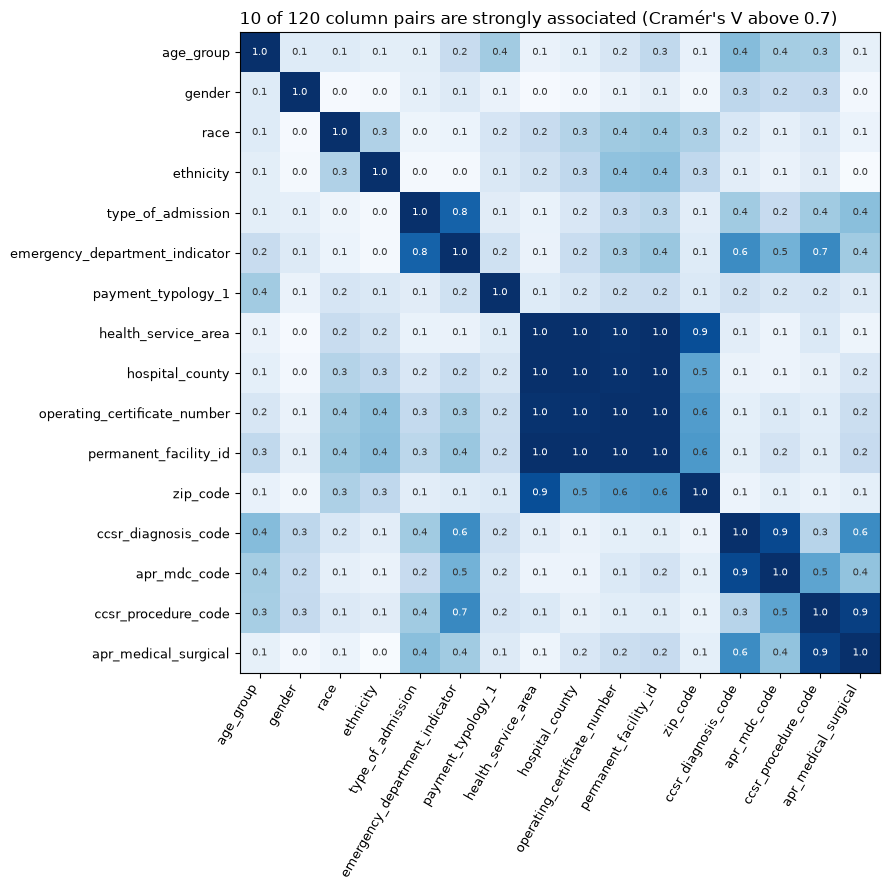

In [ ]:
import numpy as np
from scipy.stats import chi2_contingency
# Grouped: patient, admission, payer, location, clinical
cols = ["age_group", "gender", "race", "ethnicity",
        "type_of_admission", "emergency_department_indicator", "payment_typology_1",
        "health_service_area", "hospital_county", "operating_certificate_number", "permanent_facility_id", "zip_code",
        "ccsr_diagnosis_code", "apr_mdc_code", "ccsr_procedure_code", "apr_medical_surgical"]

s = df_clean[cols].sample(3000000, random_state=0)       # a sample is enough to measure association and is much faster

def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

v = pd.DataFrame(1.0, index=cols, columns=cols)
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        v.loc[a, b] = v.loc[b, a] = cramers_v(s[a], s[b])

# plot
fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(v.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=60, ha="right", fontsize=9)
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols, fontsize=9)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{v.values[i, j]:.1f}", ha="center", va="center", fontsize=7,
                color="white" if v.values[i, j] > 0.6 else "#333333")

upper = v.values[np.triu_indices(len(cols), k=1)]
ax.set_title(f"{(upper > 0.7).sum()} of {len(upper)} column pairs are strongly associated "
             f"(Cramér's V above 0.7)", loc="left")
plt.tight_layout()
plt.show()


*Observation 1: the location columns are nested.*
- Health service area, county, operating certificate and facility ID are all about 1.0 with each other. We verified earlier that each facility belongs to exactly one certificate, and a county and health service area are determined by the facility.
- the facility already determines the county, health service area and certificate, so they add no information beyond it. 
- `hospital_county`, `health_service_area` and `operating_certificate_number` are proposed to be dropped, and `permanent_facility_id` and `zip_code` are kept.

*Observation 2: medical/surgical is determined by the procedure.*
- `apr_medical_surgical` and `ccsr_procedure_code` have V = 0.9, and the HCUP documentation defines surgical by whether an operating-room procedure was performed (p. 15). `apr_medical_surgical` explains only 0.1% of the variation in length of stay.
- it is redundant given the procedure category and carries almost no signal of its own. `apr_medical_surgical` is proposed to be dropped.

*Observation 3: admission type and the ED indicator overlap.*
- `type_of_admission` and `emergency_department_indicator` have V = 0.8, but they are not copies: Urgent admissions mostly do not pass through the ED (16.33% do), while Emergency and Trauma mostly do (91.16% and 93.52%).


*Observation 4: diagnosis determines MDC.*
- `ccsr_diagnosis_code` and `apr_mdc_code` have V = 0.9, and the HCUP documentation defines MDC from the principal diagnosis (p. 15). A small share of cases is assigned an MDC through procedure rules (p. 57), so the match is 0.9 and not 1.0.
- Statement: MDC is a coarser version of the diagnosis and adds no separate information, so `apr_mdc_code` is proposed to be dropped, in the same way as `apr_medical_surgical` (determined by the procedure). 

In [127]:
# redundant_cols = [
#     "hospital_county", "health_service_area", "operating_certificate_number",   # nested under permanent_facility_id
#     "apr_medical_surgical",                                                     # determined by ccsr_procedure_code
#     "apr_mdc_code",                                                             # determined by ccsr_diagnosis_code
# ]

# df_final = df_clean.drop(columns=redundant_cols)

# print("shape:", df_final.shape)
# print(df_final.columns.tolist())
# assert not any(c in df_final.columns for c in redundant_cols)